# US Accidents: learning to predict traffic impact

**Group:** Yanis Barbieux, Kamar Benbacha, Théophile Melquiot

**Hands-on Machine Learning, M1 Computer Science**

### AI use disclosure

AI tools were used to help write and revise the documentation and Markdown,
format the notebook, define and clarify variables, and write code.

## 1. Introduction

Can the context of an accident tell us whether it will have a high impact on
traffic? Our target is **Severity 3 or 4 versus Severity 1 or 2**. Severity
describes the disruption to traffic, not the injuries and not the risk that an
accident happens.

We first worked on separate approaches and then merged them. Kamar explored the
columns and the missing values, prepared a larger sample and compared logistic
regression with two tree models. Yanis worked on time-based evaluation, repeated
events and boosting with native categories. Their differences gave us three
questions: which records should we keep, how should we encode categories, and
does a larger sample help?

This notebook builds the common approach step by step. We use Source2 only and
compare gradient boosting with a random forest and a logistic regression. Weather
is used in two ways: only what was observed before the accident started, or also
an update up to one hour after the start.

Dataset: [US Accidents, March 2023 version](https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents).
Severity definition: [creator metadata](https://www.kaggle.com/sobhanmoosavi/us-accidents/metadata).

### Related work and our contribution

**The dataset papers.** Moosavi et al., [A Countrywide Traffic Accident Dataset (2019)](https://arxiv.org/abs/1906.05409),
introduced US-Accidents with time, location, weather and nearby points of interest;
its first release is smaller than the March 2023 file we use. Their
[Accident Risk Prediction based on Heterogeneous Sparse Data (2019)](https://arxiv.org/abs/1909.09638)
describes a deep learning model that predicts whether an accident will occur, which is
a different task from predicting the traffic impact of an accident that is already
recorded. We read only the abstracts and do not compare scores with ours.

**Public projects on the same file.** We read the README of three public GitHub
projects on 14 October 2026. We did not re-run their code.

| Project | Target and split | Notable inputs | Reported result |
| --- | --- | --- | --- |
| [Atharva-Penkar](https://github.com/Atharva-Penkar/US-accidents-severity-analysis-and-prediction) | Severity 1 to 4, random 70/15/15 split | `Source` and `Year`, kept on purpose | XGBoost: macro F1 0.735, accuracy 0.908; macro F1 0.575 without `Source` and `Year` |
| [Sams-Alt-Personality](https://github.com/Sams-Alt-Personality/US-Accidents-CountryWide-Dataset) | Severity 1 to 4, sample of 300,000 accidents from 2022-2023, random 80/20 split | `Duration_Minutes` (built from the end time) and `Year` | Random forest: accuracy 0.939, macro F1 0.588, recall 0.06 on Severity 4 |
| [rayenchanchah01](https://github.com/rayenchanchah01/US_accidents) | Severity 1 to 4, 70/15/15 split and a temporal check planned | removes end time, distance and description as leakage | data preparation only, no model scores yet |

These scores cannot be compared with ours: the targets (four classes against two),
the splits (random against chronological) and the inputs are different. They still
teach us two things that shape this notebook. First, the source and the year carry a
large part of the score. The first project goes from macro F1 0.735 to 0.575 when it
removes them, and the third reports that Source2 labels 34% of its accidents
Severity 3 against 4% for Source1. This is why we keep Source2 only and evaluate in
chronological order. Second, a high accuracy on four classes mostly reflects the
dominant Severity 2 (about 92% of the accidents in the second project's sample), and
the duration of an incident is only known once it has ended. We therefore use
average precision on a binary target, and only inputs that are available at the
prediction time.

**Our contribution.** We do not expect to beat a published score; our contribution
lies in the method. We evaluate in chronological order, because the labels drift
between sources and years. We check which information is available at prediction
time, especially for the weather timestamps. We measure which groups of inputs the
model relies on, and we use metrics suited to an imbalanced target. We use existing
algorithms and focus on understanding what the data and the results allow us to
conclude.

## 2. Preprocessing

### 2.1 Set up one common configuration

We keep the main choices in one place so the study is easy to reproduce. The CSV
stays on the local machine and is not part of the submission. Install
`requirements-final-notebook.txt` and open the notebook inside the project.
The `traffic_impact/` modules only read and sample the file; the preparation
and the models are written in this notebook.

In [1]:
import os
for name in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[name] = "4"  # keep the number of threads small
from pathlib import Path
import sys, json, itertools, gc, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_recall_curve, precision_score, recall_score, f1_score, confusion_matrix)
from threadpoolctl import threadpool_limits

threadpool_limits(limits=4)  # one thread limit for every model below

# Find the project folder, the one that contains traffic_impact/.
ROOT = Path.cwd().resolve()
if (ROOT / "us_accidents_traffic_impact_prediction/traffic_impact").is_dir():
    ROOT = ROOT / "us_accidents_traffic_impact_prediction"
while not (ROOT / "traffic_impact").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "traffic_impact").is_dir(), "Open this notebook inside the project."
sys.path.insert(0, str(ROOT))
from traffic_impact.final_notebook import find_csv, load_samples, data_dictionary, nearby_keys
from traffic_impact.experiment import POI, LIGHT, WNUM, WCAT, FORBIDDEN, preprocessor
CSV_PATH = find_csv()  # Change this path if the CSV is stored elsewhere.
WORK = ROOT / "data/final_notebook"
REPORTS, FIGURES = WORK / "reports", WORK / "figures"
for path in [REPORTS, FIGURES]:
    path.mkdir(parents=True, exist_ok=True)
SEED, TRAIN_N, WEATHER_AFTER, WEATHER_CAP = 42, 500_000, 60, 25
COMPARISONS = ROOT / "results/final_notebook_comparison"
pd.set_option("display.max_columns", 9)
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 100})
display(pd.Series({"Training events": TRAIN_N, "Weather update (minutes)": WEATHER_AFTER,
    "Weather category limit": WEATHER_CAP, "Seed": SEED}, name="Common choices").to_frame())

,Common choices
Training events,500000
Weather update (minutes),60
Weather category limit,25
Seed,42


We use a fixed seed and keep the natural class proportions. Time and location
always refer to the accident start; only the weather window changes between the
two scenarios.

### 2.2 Look at the original records

Kamar began by reading a small part of the file before loading larger samples.
We keep this first step: identify the columns and their units, then look at a
few records. These first rows only show the format; they are not representative.

In [2]:
preview = pd.read_csv(CSV_PATH, nrows=5)
dictionary = data_dictionary(preview.columns)
dictionary.to_csv(REPORTS / "data_dictionary.csv", index=False)
display(preview[["Source", "Severity", "Start_Time", "State", "Temperature(F)",
                 "Weather_Timestamp"]])
ROAD = [c for c in POI if c != "Turning_Loop"]
input_groups = pd.DataFrame({
    "Group": ["Time", "Location", "Road context", "Light", "Weather"],
    "Inputs": [4, 4, len(ROAD), len(LIGHT), len(WNUM) + len(WCAT)],
    "Examples": ["hour, weekday, month, weekend", "latitude, longitude, State, Timezone",
                 "junction, crossing, signals", "day/night and twilight",
                 "temperature, visibility, wind, conditions"]})
display(input_groups)

,Source,Severity,Start_Time,State,Temperature(F),Weather_Timestamp
0,Source2,3,2016-02-08 05:46:00,OH,36.9,2016-02-08 05:58:00
1,Source2,2,2016-02-08 06:07:59,OH,37.9,2016-02-08 05:51:00
2,Source2,2,2016-02-08 06:49:27,OH,36.0,2016-02-08 06:56:00
3,Source2,3,2016-02-08 07:23:34,OH,35.1,2016-02-08 07:38:00
4,Source2,2,2016-02-08 07:39:07,OH,36.0,2016-02-08 07:53:00


,Group,Inputs,Examples
0,Time,4,"hour, weekday, month, weekend"
1,Location,4,"latitude, longitude, State, Timezone"
2,Road context,12,"junction, crossing, signals"
3,Light,4,day/night and twilight
4,Weather,9,"temperature, visibility, wind, conditions"


The file mixes numerical measurements, categories, flags and timestamps. Units
such as Fahrenheit, miles and inches are kept as recorded. The five groups give
33 logical inputs; the road group leaves out Turning_Loop, which is always False
in the audited file. The dictionary in Appendix A defines every original column,
including the ones we exclude, and the four derived time variables.

### 2.3 Work with distinct events

We read the full file in blocks when the samples must be prepared. Within each
period we draw distinct Source2 events at random (seed 42), using a priority
number that does not depend on Severity. The 200,000-event sample is a subset of
the 500,000-event sample.

An event is identified by Source, start and end time, start coordinates,
Distance and Description, but not Severity. Repeated copies of an event are
merged, and events whose copies have different Severity labels are removed, even
if their binary labels agree. These identity fields are not used as predictors.
Nearby accidents are not treated as the same event.

In [3]:
raw, audit, AUDIT_FOLDER = load_samples(CSV_PATH, WORK)
raw["train"] = raw["train"].nsmallest(TRAIN_N, "_priority").sort_values("_t").reset_index(drop=True)
audit_summary = pd.Series({"Original records": audit["rows"],
    "Original columns": audit["columns"], "Source2 records": audit["source2_rows"],
    "Repeated Source2 event records": audit["source2_duplicate_event_rows"],
    "Conflicting Source2 event keys": audit["source2_conflicting_event_keys"]}, name="Full-file audit")
display(audit_summary.to_frame())

,Full-file audit
Original records,7728394
Original columns,46
Source2 records,3305373
Repeated Source2 event records,2136
Conflicting Source2 event keys,8


The audit of the whole file separates repeated events from record identifiers.
We remove all copies of a conflicting event because the file does not say which
label is right. Sampling keeps the study manageable and keeps the natural class
proportions. Saved samples are reused only if the CSV, the preparation code, the
environment and the file hashes match.

### 2.4 Compare sources before choosing the study population

Both individual approaches looked at the data providers. We plot the share of
positive labels by source and year, using the audit of the whole file. This
shows whether mixing sources would make the target hard to interpret.

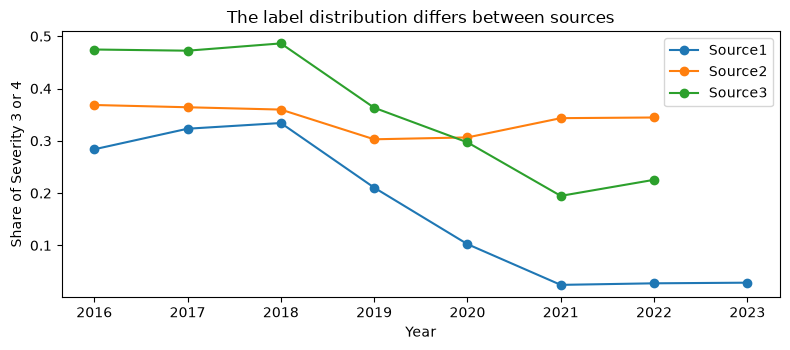

In [4]:
source_month = pd.read_csv(AUDIT_FOLDER / "monthly_source_severity.csv")
source_month["year"] = pd.to_numeric(source_month["_month"].str[:4], errors="coerce")
source_month["positives"] = source_month["count"].where(source_month.Severity.ge(3), 0)
source_year = source_month.groupby(["Source", "year"])[["count", "positives"]].sum()
source_year["positive_rate"] = source_year.positives / source_year["count"]
for source, group in source_year.reset_index().groupby("Source"):
    plt.plot(group.year, group.positive_rate, marker="o", label=source)
plt.xlabel("Year")
plt.ylabel("Share of Severity 3 or 4")
plt.title("The label distribution differs between sources")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "01_sources.png")
plt.show()

The sources have different label distributions, and these change over time. We
focus on Source2 to give the study a clear scope. This does not explain the
changes in the other sources and does not prove that Source2 is better.
Source2 ends in September 2022, so our last period is incomplete.

### 2.5 Clean invalid values without deleting incomplete weather records

Kamar removed rows with more than four missing predictors and filled the
remaining gaps with training statistics. In the common study we keep the records
without weather: their time, location and road context are still useful, and we
avoid keeping only the accidents whose weather is better documented.

A record needs a valid date and a label from 1 to 4. Impossible coordinates or
humidity and negative physical measurements become missing; plausible extreme
values stay. We never impute the target, and temperature has no arbitrary cutoff.

In [5]:
raw_clean, cleaning_rows, invalid_rows = {}, [], []
bounds = {"Start_Lat": (-90, 90), "Start_Lng": (-180, 180), "Humidity(%)": (0, 100),
    "Pressure(in)": (0, np.inf), "Visibility(mi)": (0, np.inf),
    "Wind_Speed(mph)": (0, np.inf), "Precipitation(in)": (0, np.inf)}
for split, original in raw.items():
    frame = original.copy()
    frame["_t"] = pd.to_datetime(frame.Start_Time, format="mixed", errors="coerce")
    valid = frame._t.notna() & frame.Severity.isin([1, 2, 3, 4])
    cleaning_rows.append({"Period": split, "Before": len(frame),
        "Invalid date/label": int((~valid).sum()), "After": int(valid.sum())})
    frame = frame.loc[valid].reset_index(drop=True)
    for column, (lower, upper) in bounds.items():
        values = pd.to_numeric(frame[column], errors="coerce")
        bad = values.notna() & (~values.between(lower, upper) | ~np.isfinite(values))
        invalid_rows.append({"split": split, "column": column, "changed": int(bad.sum())})
        frame[column] = values.mask(bad)
    raw_clean[split] = frame
cleaning = pd.DataFrame(cleaning_rows)
invalid = pd.DataFrame(invalid_rows)
display(cleaning)
display(invalid.groupby("column").changed.sum().rename("Invalid values replaced").to_frame())
cleaning.to_csv(REPORTS / "record_cleaning.csv", index=False)
invalid.to_csv(REPORTS / "numeric_cleaning.csv", index=False)

,Period,Before,Invalid date/label,After
0,train,500000,0,500000
1,validation,50000,0,50000
2,test,99999,0,99999
3,stress,50000,0,50000


,Invalid values replaced
column,
Humidity(%),0
Precipitation(in),0
Pressure(in),0
Start_Lat,0
Start_Lng,0
Visibility(mi),0
Wind_Speed(mph),0


These samples contain no invalid dates, labels or values under the physical
bounds above, so this step changes nothing here. That does not prove the whole
file is error-free. Keeping incomplete weather is a choice about which accidents
we study; we did not show that it beats Kamar's row-removal policy.

### 2.6 Keep the evaluation in chronological order

Kamar used evaluation years that start and end in September; Yanis used calendar
years. The common study keeps calendar years because they are simpler to explain.
We learn on 2016-2019, compare settings on 2020, and look at 2021 and the
available part of 2022 afterwards. Labels stay separate from the predictors.

,Period,Events,Positive share (%),First date,Last date
0,2016-2019 (train),500000,34.4,2016-02-08,2019-12-31
1,2020 (validation),50000,30.3,2020-01-01,2020-12-31
2,2021 (historical),99999,34.3,2021-01-01,2021-12-31
3,2022 to Sep 8,50000,34.7,2022-01-01,2022-09-08


The positive share is **34.4%** in 2016-2019, **30.3%** in 2020, **34.3%** in 2021 and **34.7%** in the available part of 2022.

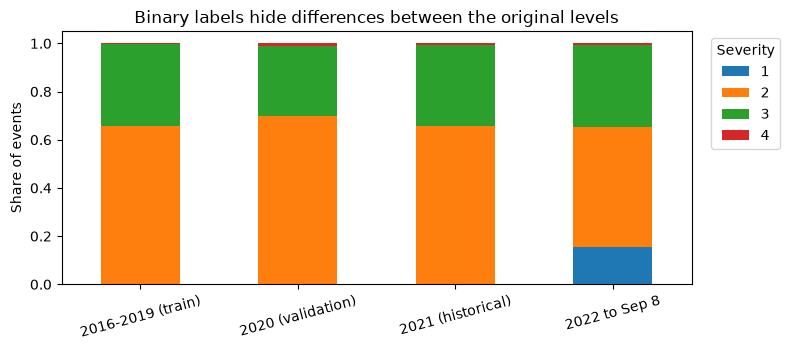

In [6]:
period_names = {"train": "2016-2019 (train)", "validation": "2020 (validation)",
    "test": "2021 (historical)", "stress": "2022 to Sep 8"}
y = {s: d.Severity.ge(3).to_numpy(dtype="int8") for s, d in raw_clean.items()}
sample_table = pd.DataFrame([{"Period": period_names[s], "Events": len(d),
    "Positive share (%)": round(100 * y[s].mean(), 1),
    "First date": str(d._t.min().date()), "Last date": str(d._t.max().date())}
    for s, d in raw_clean.items()])
display(sample_table)
shares = {s: 100 * y[s].mean() for s in y}
display(Markdown(f"The positive share is **{shares['train']:.1f}%** in 2016-2019, "
    f"**{shares['validation']:.1f}%** in 2020, **{shares['test']:.1f}%** in 2021 "
    f"and **{shares['stress']:.1f}%** in the available part of 2022."))
levels = pd.DataFrame({period_names[s]: d.Severity.value_counts().reindex([1, 2, 3, 4], fill_value=0)
    for s, d in raw_clean.items()}).T
levels.div(levels.sum(axis=1), axis=0).plot.bar(stacked=True, figsize=(8, 3.6))
plt.ylabel("Share of events")
plt.xlabel("")
plt.xticks(rotation=15)
plt.legend(title="Severity", bbox_to_anchor=(1.02, 1))
plt.title("Binary labels hide differences between the original levels")
plt.tight_layout()
plt.savefig(FIGURES / "02_levels.png")
plt.show()

About one third of the sampled accidents are positive, so accuracy alone would
be misleading. Most positives are Severity 3; Severity 4 is rare. The share of
Severity 1 also changes in 2022. We already looked at 2021 and 2022 during the
project, so they are historical evaluations, not new independent tests.

2020, our validation year, has fewer positives than the other years. The
COVID-19 period may have changed traffic and recording, but we have not shown
this. It matters for two reasons. AP and ROC-AUC measure how well accidents are
ranked, so they can be compared across years, although AP also depends on the
positive share. The F1 threshold, however, is fixed on 2020 and then applied to
years with more positives without being tuned again. Finally, 2022 stops on
8 September, so 2021 is our only complete evaluation year.

### 2.7 Derive features that describe the accident context

Following the individual notebooks, we turn Start_Time into hour, weekday,
month and a weekend flag. We keep start location, nearby road features and
the light indicators. End time, end coordinates, Distance and Description
are excluded because their initial availability is not established.

,hour,day_of_week,month,weekend
0,8,0,2,0
1,9,0,2,0
2,12,0,2,0
3,15,0,2,0
4,20,0,2,0


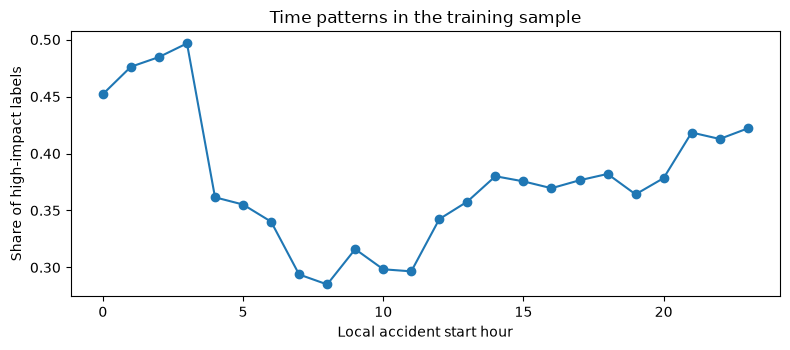

In [7]:
def initial_features(frame):
    time = frame["_t"]
    result = pd.DataFrame({"hour": time.dt.hour, "day_of_week": time.dt.dayofweek,
        "month": time.dt.month, "weekend": time.dt.dayofweek.ge(5).astype(int)})
    for column in ["Start_Lat", "Start_Lng", "State", "Timezone"] + POI + LIGHT + WNUM + WCAT:
        result[column] = frame[column]
    for column in POI:
        result[column] = result[column].astype(float)
    for column in ["State", "Timezone"] + LIGHT + WCAT:
        result[column] = result[column].astype("string")
    return result

initial = {s: initial_features(d) for s, d in raw_clean.items()}
display(initial["train"][["hour", "day_of_week", "month", "weekend"]].head())
by_hour = pd.Series(y["train"]).groupby(initial["train"].hour).mean()
by_hour.plot(marker="o")
plt.xlabel("Local accident start hour")
plt.ylabel("Share of high-impact labels")
plt.title("Time patterns in the training sample")
plt.tight_layout()
plt.savefig(FIGURES / "03_hour.png")
plt.show()

The curve shows an association in the training data, not a causal effect of the
hour. We do not use the year as a predictor. Turning_Loop is always False in the
audited file, so it carries no signal and is left out, which gives 33 inputs
(see 2.11). The day/night indicators describe natural light at the start, not
artificial road lighting.

### 2.8 Clarify the two weather scenarios with an example

The file contains one weather observation already associated with each
accident. We check its timestamp; we cannot retrieve a different reading.
Kamar accepted observations within two hours before or after the start.
Yanis initially accepted only the two preceding hours. We compare that strict
rule with an update allowing up to one hour after the start.

In [8]:
example = pd.DataFrame({"Accident start": ["10:00"] * 5,
    "Associated observation": ["07:59", "08:00", "09:30", "10:30", "11:01"],
    "Offset (minutes)": [-121, -120, -30, 30, 61]})
example["At start"] = example["Offset (minutes)"].between(-120, 0)
example["With update"] = example["Offset (minutes)"].between(-120, 60)
display(example)

,Accident start,Associated observation,Offset (minutes),At start,With update
0,10:00,07:59,-121,False,False
1,10:00,08:00,-120,True,True
2,10:00,09:30,-30,True,True
3,10:00,10:30,30,False,True
4,10:00,11:01,61,False,False


This is an illustrative example, not five sampled accidents. A 10:30 observation
cannot be used for a prediction made at 10:00, so the update describes a later
prediction. Even an eligible timestamp does not tell us when the reading was
published. Other fields from the future do not get this weather exception.

### 2.9 Apply the weather rule and harmonise wind labels

All nine weather fields are masked together if the timestamp is missing or
outside the chosen window. The accident remains. We also merge spelling
variants such as East/E, without merging different directions such as NE/NW.

In [9]:
aliases = {"NORTH": "N", "SOUTH": "S", "EAST": "E", "WEST": "W",
    "CALM": "Calm", "VAR": "Variable", "VARIABLE": "Variable"}

def weather_offset(frame):
    """Minutes between the accident start and its associated weather observation."""
    observed = pd.to_datetime(frame.Weather_Timestamp, format="mixed", errors="coerce")
    return (observed - frame["_t"]).dt.total_seconds() / 60

def mask_weather(inputs, eligible):
    """Keep the weather fields only when the observation falls inside the window."""
    result = inputs.copy()
    for column in WNUM:
        result[column] = pd.to_numeric(result[column], errors="coerce").where(eligible)
    for column in WCAT:
        values = result[column]
        if column == "Wind_Direction":
            values = values.str.strip().str.upper().replace(aliases)
        result[column] = values.where(eligible)
    return result

features, weather_rows = {}, []
for split, frame in raw_clean.items():
    offset = weather_offset(frame)
    features[split] = mask_weather(initial[split], offset.between(-120, WEATHER_AFTER))
    for after, scenario in [(0, "At start"), (WEATHER_AFTER, "With update")]:
        weather_rows.append({"Period": period_names[split], "Scenario": scenario,
            "Eligible timestamps (%)": round(100 * offset.between(-120, after).mean(), 1)})
weather_table = pd.DataFrame(weather_rows)
display(weather_table[weather_table.Period.eq(period_names["validation"])])
weather_table.to_csv(REPORTS / "weather_coverage.csv", index=False)

,Period,Scenario,Eligible timestamps (%)
2,2020 (validation),At start,50.4
3,2020 (validation),With update,97.9


The wider window keeps substantially more associated observations. Timestamp
eligibility is not the same as complete weather: individual fields can still
be missing. We retain the update as the main scenario and keep the strict rule
as a comparison, with its different prediction time clearly stated.

### 2.10 Inspect missing values before deciding how to handle them

Kamar's missingness analysis showed why removing every incomplete row would
discard too much data. Here we compare the same training events before and
after timestamp masking. The masking can increase missingness without deleting
records. Boosting can retain numerical gaps; the forest and the logistic
regression need complete values.

,Before timestamp rule (%),After timestamp rule (%)
Temperature(F),1.7,2.6
Wind_Chill(F),64.1,64.3
Humidity(%),1.8,2.7
Pressure(in),1.5,2.4
Visibility(mi),2.0,3.0
Wind_Speed(mph),15.2,15.9
Precipitation(in),68.5,68.6
Wind_Direction,1.4,2.3
Weather_Condition,2.0,3.0


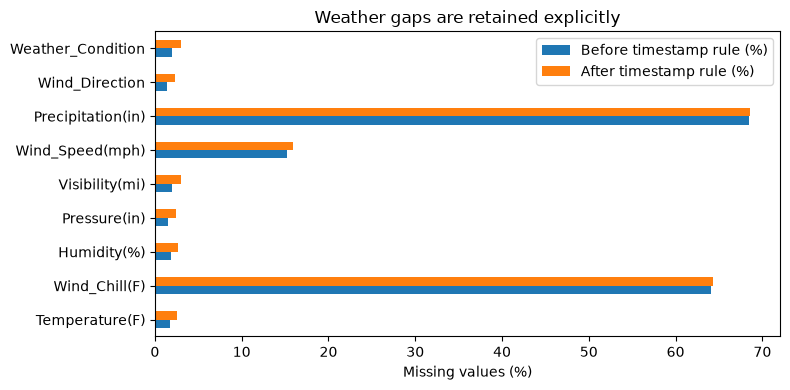

In [10]:
missingness = pd.DataFrame({"Before timestamp rule (%)": initial["train"].isna().mean() * 100,
    "After timestamp rule (%)": features["train"].isna().mean() * 100})
missingness = missingness.loc[WNUM + WCAT].round(1)
display(missingness)
missingness.plot.barh(figsize=(8, 4))
plt.xlabel("Missing values (%)")
plt.ylabel("")
plt.title("Weather gaps are retained explicitly")
plt.tight_layout()
plt.savefig(FIGURES / "04_missingness.png")
plt.show()
missingness.to_csv(REPORTS / "missingness_before_after.csv")

Precipitation and wind chill have the most missing values in the training
sample, even before timestamp masking. Missing weather does not erase the other
context. Each model uses an appropriate representation of absence. This does
not show that missingness itself causes higher or lower traffic impact.

### 2.11 Learn categorical vocabularies on training data only

We keep Kamar's idea of grouping rare weather conditions into Other. A category
needs at least 100 training occurrences, and Weather_Condition keeps at most the
25 most frequent labels. Missing is kept apart from Other. Later periods cannot
change the category lists. Numerical and road inputs use compact types.

In [11]:
class CategoryPreparation:
    """Learn the category lists on the training period, then apply them to any period."""
    def __init__(self, weather_cap=25):
        self.weather_cap = weather_cap

    def fit(self, frame):
        # Inputs that never change in training (Turning_Loop) are dropped.
        self.columns = [c for c in frame if frame[c].nunique(dropna=False) > 1]
        self.vocab = {}
        for column in self.columns:
            if pd.api.types.is_string_dtype(frame[column].dtype):
                counts = frame[column].value_counts()
                keep = counts[counts >= 100].index.tolist()   # at least 100 training events
                if column == "Weather_Condition":
                    keep = keep[:self.weather_cap]            # most frequent conditions only
                self.vocab[column] = [str(v) for v in keep if v not in ["Missing", "Other"]]
        return self

    def transform(self, frame):
        result = frame[self.columns].copy()
        for column, vocabulary in self.vocab.items():
            values = result[column].fillna("Missing").astype(str)
            values = values.where(values.isin(vocabulary + ["Missing"]), "Other")
            result[column] = pd.Categorical(values, categories=vocabulary + ["Missing", "Other"])
        for column in self.columns:
            if column not in self.vocab:
                result[column] = result[column].astype("float32")
        return result

category_prep = CategoryPreparation(WEATHER_CAP).fit(features["train"])
X = {s: category_prep.transform(frame) for s, frame in features.items()}
display(pd.DataFrame([{"Feature": c, "Retained training labels": len(v),
    "Missing label": "Missing", "Rare/unseen label": "Other"} for c, v in category_prep.vocab.items()]))

,Feature,Retained training labels,Missing label,Rare/unseen label
0,State,40,Missing,Other
1,Timezone,4,Missing,Other
2,Sunrise_Sunset,2,Missing,Other
3,Civil_Twilight,2,Missing,Other
4,Nautical_Twilight,2,Missing,Other
5,Astronomical_Twilight,2,Missing,Other
6,Wind_Direction,18,Missing,Other
7,Weather_Condition,25,Missing,Other


The category lists are learned once and reused for all periods. The native
categorical type tells boosting that categories have no numerical order. Columns
that are constant in training are dropped, which removes Turning_Loop and leaves
33 logical inputs. We have not shown that each of them is necessary.

### 2.12 Make the transformations concrete

We look at a few real category transformations and at a small one-hot example.
One-hot creates one indicator per category: it does not invent an order between
states, but it adds columns. We adapt the preparation to each model instead of
assuming one representation is best for all of them.

In [12]:
transformed = pd.DataFrame({"Recorded wind": raw_clean["train"].Wind_Direction.astype("string"),
    "After weather/spelling rule": features["train"].Wind_Direction,
    "Final wind category": X["train"].Wind_Direction.astype("string")})
display(transformed.drop_duplicates().head(8).fillna("<missing>"))
display(pd.get_dummies(pd.DataFrame({"State": ["CA", "NY", "TX"]}), dtype=int))
transformation_summary = pd.DataFrame([{"Step": "Start_Time to four time inputs", "Output": "hour, weekday, month, weekend"},
    {"Step": "Boolean road indicators", "Output": "0/1"},
    {"Step": "Weather outside window", "Output": "Missing weather; accident kept"},
    {"Step": "Rare or new categorical value", "Output": "Other"},
    {"Step": "Missing categorical value", "Output": "Missing"}])
display(transformation_summary)

,Recorded wind,After weather/spelling rule,Final wind category
0,WNW,WNW,WNW
1,WSW,WSW,WSW
2,West,W,W
3,NNE,NNE,NNE
6,SW,SW,SW
20,NW,NW,NW
21,SSW,SSW,SSW
23,Variable,Variable,Variable


,State_CA,State_NY,State_TX
0,1,0,0
1,0,1,0
2,0,0,1


,Step,Output
0,Start_Time to four time inputs,"hour, weekday, month, weekend"
1,Boolean road indicators,0/1
2,Weather outside window,Missing weather; accident kept
3,Rare or new categorical value,Other
4,Missing categorical value,Missing


The wind table shows real transformations. The three-state table is only a
teaching example. One-hot adds no new observations and does not fill weather
gaps. We use native categories for boosting and one-hot for the forest and the
logistic regression. We did not compare the two encodings with the same boosting
model.

## 3. Training

### From Kamar's first models to the common comparison

Kamar trained a constant baseline, logistic regression, boosting and a forest
on her prepared data. Logistic regression improved on the baseline; both tree
models performed better on her validation, with boosting ahead of the forest.
This gave us a useful reason to examine trees more closely.

We do not directly rank Kamar's and Yanis's notebooks: their periods, samples
and preprocessing differ. Below, boosting and the forest are trained again
on a shared protocol. Théophile's work is the linear reference in 3.5: a
logistic regression retrained on the same protocol, with its regularisation
chosen on 2020. Settings are chosen on 2020; later years do not select them.

### 3.1 Check model capacity, then training volume

Boosting builds trees one after another, each correcting the errors of the
previous ones. A larger leaf limit lets a tree separate more combinations of
conditions, and more iterations add more correction steps. Both can also make the
model fit details of the training data too closely. We fit three settings on
2016-2019 and compare their AP on 2020. Everything else is the same as in the
main model, and the 63-leaf, 400-iteration model is the main model itself, used
in the rest of the notebook.

In [13]:
boosting_settings = {"max_iter": 400, "max_leaf_nodes": 63, "learning_rate": 0.1,
    "categorical_features": "from_dtype", "early_stopping": False, "random_state": SEED}
capacity_rows, capacity_models = [], {}
for leaves, iterations in [(31, 200), (63, 200), (63, 400)]:
    model = HistGradientBoostingClassifier(
        **{**boosting_settings, "max_leaf_nodes": leaves, "max_iter": iterations})
    start = time.perf_counter()
    model.fit(X["train"], y["train"])
    fit_seconds = time.perf_counter() - start
    capacity_models[(leaves, iterations)] = model
    capacity_rows.append({"Maximum leaves": leaves, "Iterations": iterations,
        "Validation AP": average_precision_score(y["validation"], model.predict_proba(X["validation"])[:, 1]),
        "Fit seconds": fit_seconds})
boosting = capacity_models[(63, 400)]  # the main model
capacity = pd.DataFrame(capacity_rows)
display(capacity.round({"Validation AP": 3, "Fit seconds": 0}))
capacity.to_csv(REPORTS / "boosting_capacity.csv", index=False)
validation_trials = pd.read_csv(COMPARISONS / "validation.csv")
volume_names = ["e19_hgb_200000_w60_c25_refined", "e21_hgb_500000_w60_c25_refined"]
volume = validation_trials.set_index("name").loc[volume_names, ["train_n", "ap"]]
display(volume.rename(columns={"train_n": "Training events", "ap": "Validation AP"}).reset_index(drop=True).round(3))

,Maximum leaves,Iterations,Validation AP,Fit seconds
0,31,200,0.715,24.0
1,63,200,0.735,29.0
2,63,400,0.748,44.0


,Training events,Validation AP
0,200000,0.729
1,500000,0.748


The capacity table is computed in this run. It supports 63 leaves per tree and
400 iterations, at a higher training cost. The volume table is different: it
reports results recorded in our earlier common comparisons and is not recomputed
here. With the selected settings, the larger sample improved the validation AP,
so we keep 500,000 events. We changed one thing at a time; these results do not
show a universal optimum.

### 3.2 Refine the weather grouping and check the prediction-time tradeoff

The number of frequent Weather_Condition labels is a separate preparation choice.
We also compare the strict and the updated weather scenarios at the reference
model settings. Each question has a small table with one metric. Both tables
report results recorded in our earlier common comparisons; they are not
recomputed in this notebook.

In [14]:
category_names = ["e20_hgb_500000_w60_c10_refined", "e12_hgb_500000_w60_c15", "e21_hgb_500000_w60_c25_refined"]
categories = validation_trials.set_index("name").loc[category_names, ["cap", "ap"]]
display(categories.rename(columns={"cap": "Weather category limit", "ap": "Validation AP"}).reset_index(drop=True).round(3))
weather_comparison = validation_trials.set_index("name").loc[
    ["e05_hgb_500000_w0_c15", "e07_hgb_500000_w60_c15"], ["after", "ap"]].copy()
weather_comparison.index = ["At start", "With update"]
display(weather_comparison.rename(columns={"after": "Minutes after start allowed", "ap": "Validation AP"}).round(3))

,Weather category limit,Validation AP
0,10,0.747
1,15,0.746
2,25,0.748


,Minutes after start allowed,Validation AP
At start,0,0.705
With update,60,0.713


A limit of 25 has the highest AP of the three limits, but the differences are
small, so this is a minor refinement. The weather update gives a small gain at
the reference settings and many more usable timestamps. We did not measure this
gain again with the final settings. The update also means predicting at a later
time than the strict scenario.

### 3.3 Describe the main boosting model

Boosting builds trees sequentially using the gradient of the loss. Numerical
bins make its split search efficient; categorical inputs are handled natively.
The selected configuration was already trained on 2016-2019 in 3.1; we reuse
it without refitting. There is no class weighting, synthetic balancing or
random early-stopping split.

In [15]:
prior = float(y["train"].mean())
display(pd.Series({"Training events": len(y["train"]), "Logical inputs": X["train"].shape[1],
    "Maximum leaves per tree": boosting.max_leaf_nodes, "Iterations": boosting.n_iter_}, name="Boosting").to_frame())

,Boosting
Training events,500000
Logical inputs,33
Maximum leaves per tree,63
Iterations,400


The model uses the larger sample and the selected tree capacity. The constant
baseline assigns the training positive share to every accident; it will help
us judge how much the context improves ranking.

### 3.4 Fit a forest with its own preparation

A random forest averages many trees, each fitted on a bootstrap sample and on a
random subset of the inputs at each split. We keep 100 trees and at least five
events per leaf, as selected on the common validation. Numerical gaps receive
training medians and categories become one-hot indicators. The forest uses a
weather limit of 15 categories while boosting uses 25: each model keeps the setup
that was validated for it.

Wind chill is one of the most incomplete inputs (see 2.10). The official formula
only applies up to 50 °F and for winds of at least 3 mph; otherwise the felt
temperature is simply the air temperature. A missing wind chill may therefore
often mean "same as the temperature" rather than "unknown". We test this idea
instead of assuming it: we fit the forest twice, with the training median or with
the temperature of the same accident (after the weather rule of 2.9), and keep the
option with the higher AP on 2020. Boosting keeps its native missing values.

In [16]:
forest_categories = CategoryPreparation(weather_cap=15).fit(features["train"])

def fill_wind_chill(frame):
    """A missing wind chill takes the air temperature of the same accident."""
    result = frame.copy()
    result["Wind_Chill(F)"] = result["Wind_Chill(F)"].fillna(result["Temperature(F)"])
    return result

def forest_scores(model, prep, inputs, split):
    """Probability of high impact given by a fitted forest, for one period."""
    encoded = prep.transform(forest_categories.transform(inputs[split]))
    return model.predict_proba(encoded.astype("float32").toarray())[:, 1]

wind_chill_options = {"Training median": features,
    "Temperature, then training median": {s: fill_wind_chill(f) for s, f in features.items()}}
forest_fits = {}
for option, inputs in wind_chill_options.items():
    train = forest_categories.transform(inputs["train"])
    prep = preprocessor(train)
    model = RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
        max_features="sqrt", random_state=SEED, n_jobs=4)
    model.fit(prep.fit_transform(train).astype("float32").toarray(), y["train"])
    ap = average_precision_score(y["validation"], forest_scores(model, prep, inputs, "validation"))
    forest_fits[option] = {"model": model, "prep": prep, "ap": ap}
    gc.collect()  # free memory between the two fits

wind_chill_choice = pd.DataFrame({"Missing Wind_Chill(F)": list(forest_fits),
    "Forest validation AP": [fit["ap"] for fit in forest_fits.values()]})
display(wind_chill_choice.round(4))
wind_chill_choice.to_csv(REPORTS / "wind_chill_choice.csv", index=False)
wind_chill_option = max(forest_fits, key=lambda option: forest_fits[option]["ap"])
forest_inputs = wind_chill_options[wind_chill_option]
forest, forest_pre = forest_fits[wind_chill_option]["model"], forest_fits[wind_chill_option]["prep"]
chosen_ap = forest_fits[wind_chill_option]["ap"]
other_ap = min(fit["ap"] for fit in forest_fits.values())
display(Markdown(f"The forest keeps **{wind_chill_option.lower()}** for missing wind chill "
    f"(2020 AP {chosen_ap:.4f}, against {other_ap:.4f} for the other option)."))
del forest_fits  # keep only the selected forest in memory
gc.collect()
display(pd.Series({"Training events": len(y["train"]), "Logical inputs": len(forest_categories.columns),
    "Encoded columns": forest.n_features_in_, "Trees": forest.n_estimators,
    "Missing wind chill": wind_chill_option}, name="Forest").to_frame())

,Missing Wind_Chill(F),Forest validation AP
0,Training median,0.6965
1,"Temperature, then training median",0.6949


The forest keeps **training median** for missing wind chill (2020 AP 0.6965, against 0.6949 for the other option).

,Forest
Training events,500000
Logical inputs,33
Encoded columns,119
Trees,100
Missing wind chill,Training median


The forest is a real trained competitor. Its encoded matrix has more columns than
the 33 inputs because one categorical input becomes several indicators. Medians
and encoding rules are fitted on training data only. The two wind chill options
give close AP on 2020, and the code keeps the better one (shown above). In our
run it is the plain training median, so the temperature fill, although it makes
physical sense, brings no gain; the logistic regression below uses the same
option. As for every other setting, the choice is made on 2020 only. The
comparison is between complete pipelines, not between algorithms with identical
encodings.

### 3.5 Add a linear reference with logistic regression

Logistic regression combines the inputs linearly and passes the result through a
sigmoid. It cannot represent interactions unless we create them, which makes it a
useful reference: it shows how much the trees gain from non-linear combinations.
It uses the forest's categories and wind chill option, one-hot indicators,
training medians and standardised numerical inputs, so that the penalty treats all
coefficients on the same scale. We choose the inverse regularisation strength C
among 0.1, 1 and 10 using the AP on 2020.

In [17]:
def logistic_inputs(split):
    return forest_categories.transform(forest_inputs[split])

logistic_pre = preprocessor(logistic_inputs("train"), scale=True)
logistic_train = logistic_pre.fit_transform(logistic_inputs("train"))
logistic_validation = logistic_pre.transform(logistic_inputs("validation"))
logistic_models, logistic_rows = {}, []
for C in [0.1, 1, 10]:
    model = LogisticRegression(C=C, max_iter=2000)
    model.fit(logistic_train, y["train"])
    logistic_models[C] = model
    logistic_rows.append({"C": C, "Iterations used": int(model.n_iter_[0]),
        "Validation AP": average_precision_score(y["validation"], model.predict_proba(logistic_validation)[:, 1])})
logistic_choice = pd.DataFrame(logistic_rows)
display(logistic_choice.round(4))
logistic_choice.to_csv(REPORTS / "logistic_choice.csv", index=False)
logistic_C = float(logistic_choice.loc[logistic_choice["Validation AP"].idxmax(), "C"])
logistic = logistic_models[logistic_C]
display(pd.Series({"Training events": len(y["train"]), "Encoded columns": logistic_train.shape[1],
    "Selected C": logistic_C}, name="Logistic regression").to_frame())
del logistic_train, logistic_validation, logistic_models

,C,Iterations used,Validation AP
0,0.1,136,0.5496
1,1.0,147,0.5492
2,10.0,191,0.5493


,Logistic regression
Training events,500000.0
Encoded columns,119.0
Selected C,0.1


The regularisation strength is chosen on 2020 only and then kept fixed. The three
values give almost the same AP: with 500,000 training events, the penalty changes
little. The iteration counts stay below the limit, so the optimiser converged.
The comparison with the trees follows in 3.6.

### 3.6 Compare validation predictions and fix decision thresholds

AP summarises precision over all recall levels and measures how well accidents
are ranked. ROC-AUC measures how well positives are ranked above negatives.
Neither is classification accuracy. For binary decisions we choose, for each
model, the threshold that maximises F1 on validation, and we keep it fixed for
the later years.

In [18]:
def evaluate(target, prediction, threshold, tie_break):
    """Scores of one model on one period."""
    positive = prediction >= threshold
    # Highest 10% of the scores; ties are broken with a fixed order that ignores the labels.
    top = np.lexsort((tie_break, -prediction))[:int(np.ceil(0.10 * len(target)))]
    return {"Events": len(target), "Positive share": float(target.mean()),
        "AP": average_precision_score(target, prediction), "ROC-AUC": roc_auc_score(target, prediction),
        "Precision": precision_score(target, positive, zero_division=0),
        "Recall": recall_score(target, positive, zero_division=0),
        "F1": f1_score(target, positive, zero_division=0), "Threshold": float(threshold),
        "Precision top 10%": float(target[top].mean()),
        "Recall top 10%": float(target[top].sum() / target.sum())}

def f1_threshold(target, prediction):
    """Score threshold with the best F1."""
    precision, recall, thresholds = precision_recall_curve(target, prediction)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[np.argmax(f1)])

def predict_all(split):
    """Scores of the three fitted models on one period."""
    return {"Boosting": boosting.predict_proba(X[split])[:, 1],
        "Forest": forest_scores(forest, forest_pre, forest_inputs, split),
        "Logistic": logistic.predict_proba(logistic_pre.transform(logistic_inputs(split)))[:, 1]}

tie_break = {s: frame._priority.to_numpy() for s, frame in raw_clean.items()}
predictions = {s: {"Constant": np.full(len(y[s]), prior)} for s in y}
predictions["validation"].update(predict_all("validation"))
thresholds = {name: f1_threshold(y["validation"], values)
    for name, values in predictions["validation"].items()}
score_rows = [{"Period": "validation", "Model": name,
    **evaluate(y["validation"], values, thresholds[name], tie_break["validation"])}
    for name, values in predictions["validation"].items()]
validation_scores = pd.DataFrame(score_rows)
display(validation_scores[["Model", "AP", "ROC-AUC", "Precision", "Recall", "F1"]].round(3))

,Model,AP,ROC-AUC,Precision,Recall,F1
0,Constant,0.303,0.500,0.303,1.000,0.465
1,Boosting,0.748,0.880,0.633,0.800,0.706
2,Forest,0.697,0.845,0.580,0.775,0.663
3,Logistic,0.550,0.758,0.444,0.830,0.578


On the common validation data, boosting is the best of the settings we examined,
so it is our main model. The forest and the logistic regression also improve on
the constant baseline, and the gap between the linear model and the trees
suggests that combinations of conditions carry useful signal. The validation F1
is optimistic, because the threshold is chosen on the same data. Parameters,
category lists and thresholds are now fixed before the evaluation on later
periods.

### 3.7 Check two other boosting libraries

Our main model is scikit-learn's HistGradientBoosting. LightGBM and XGBoost are
two popular libraries that implement the same idea. We trained both in a separate
script (`scripts/compare_lightgbm.py`) with equivalent settings (63 leaves, 400
trees, learning rate 0.1), the same 33 inputs, the same periods and the same
threshold rule fixed on 2020. Their scores are saved in `results/lightgbm_comparison/`,
so the table below is read from that file and not recomputed here.

In [19]:
other_boosting = pd.read_csv(ROOT / "results/lightgbm_comparison/scores.csv")
other_boosting = other_boosting.pivot(index="Model", columns="Period", values="AP")
other_boosting = other_boosting.loc[["Boosting", "LightGBM", "XGBoost"], ["validation", "test", "stress"]]
other_boosting.columns = ["2020", "2021", "2022 to Sep 8"]
display(other_boosting.round(3))

,2020,2021,2022 to Sep 8
Model,,,
Boosting,0.748,0.752,0.754
LightGBM,0.745,0.752,0.753
XGBoost,0.746,0.754,0.755


The three libraries differ by about 0.003 AP at most in every period, so the choice
of library does not change our conclusions. We keep scikit-learn's model, which
performs as well and keeps the notebook simple. LightGBM trains faster in the
script (about 12 seconds instead of 36), which would matter with more data or a
larger search.

### 3.8 See which inputs the main model relies on

Permutation importance shuffles one input on 2020 and measures how much the AP of
the boosting model drops; the model is not refitted. Correlated inputs share their
importance: if we shuffle latitude alone, State and longitude still carry similar
information, so each input can look less important than the location as a whole.
We therefore also shuffle each group of inputs from 2.2 together, keeping the same
row order inside the group. Every measure is repeated five times.

,Group,Inputs,AP drop,Std
1,Location,4,0.3208,0.0026
2,Road context,12,0.1257,0.0010
0,Time,4,0.0869,0.0021
4,Weather,9,0.0110,0.0005
3,Light,4,0.0004,0.0001


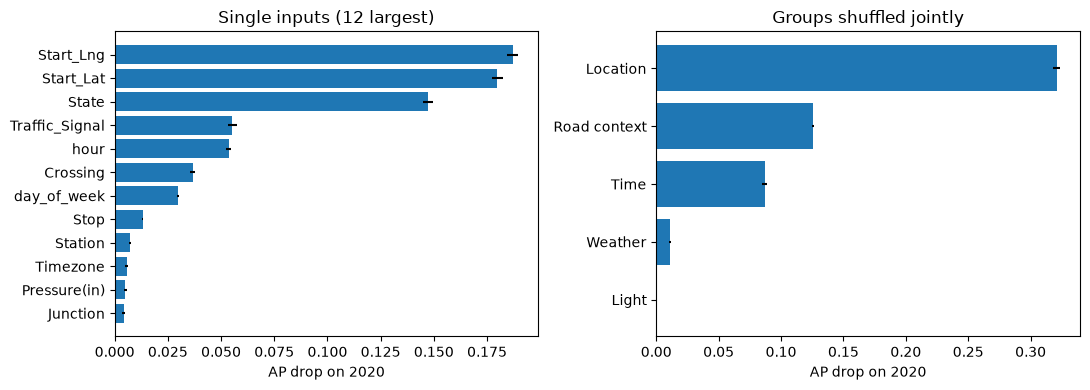

In [20]:
single = permutation_importance(boosting, X["validation"], y["validation"],
    scoring="average_precision", n_repeats=5, random_state=SEED)
single_importance = pd.DataFrame({"Input": X["validation"].columns,
    "AP drop": single.importances_mean, "Std": single.importances_std}).sort_values("AP drop", ascending=False)

input_group_columns = {"Time": ["hour", "day_of_week", "month", "weekend"],
    "Location": ["Start_Lat", "Start_Lng", "State", "Timezone"], "Road context": ROAD,
    "Light": LIGHT, "Weather": WNUM + WCAT}
reference_ap = average_precision_score(y["validation"], predictions["validation"]["Boosting"])
rng = np.random.RandomState(SEED)

def group_ap_drop(columns, repeats=5):
    """Shuffle a whole group of inputs together and measure how much the AP falls."""
    drops = []
    for _ in range(repeats):
        order = rng.permutation(len(X["validation"]))
        shuffled = X["validation"].copy()
        for column in columns:
            shuffled[column] = shuffled[column].iloc[order].set_axis(shuffled.index)
        drops.append(reference_ap - average_precision_score(
            y["validation"], boosting.predict_proba(shuffled)[:, 1]))
    return np.mean(drops), np.std(drops)

group_rows = []
for group, columns in input_group_columns.items():
    columns = [c for c in columns if c in X["validation"]]
    drop, std = group_ap_drop(columns)
    group_rows.append({"Group": group, "Inputs": len(columns), "AP drop": drop, "Std": std})
group_importance = pd.DataFrame(group_rows).sort_values("AP drop", ascending=False)
display(group_importance.round(4))
single_importance.to_csv(REPORTS / "permutation_inputs.csv", index=False)
group_importance.to_csv(REPORTS / "permutation_groups.csv", index=False)
top_inputs = single_importance.head(12).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(top_inputs.Input, top_inputs["AP drop"], xerr=top_inputs.Std)
axes[0].set(xlabel="AP drop on 2020", title="Single inputs (12 largest)")
groups_plot = group_importance.iloc[::-1]
axes[1].barh(groups_plot.Group, groups_plot["AP drop"], xerr=groups_plot.Std)
axes[1].set(xlabel="AP drop on 2020", title="Groups shuffled jointly")
plt.tight_layout()
plt.savefig(FIGURES / "05_importance.png")
plt.show()

These drops show what the fitted model uses to rank the 2020 accidents. They are
not causal effects: an input can matter because it is linked to how accidents were
recorded, and a small drop does not prove that a factor has no influence on
traffic. A group's drop can be larger than that of any single input, because its
inputs can no longer replace each other. The importance is measured on validation
and was not used to select inputs.

## 4. Evaluation

### 4.1 Examine later periods with the fixed models

We apply the fitted models and unchanged preparations to 2021 and the
available part of 2022. We keep the table compact and compare AP with the
prevalence reference, since the positive share changes between years.

In [21]:
for split in ["test", "stress"]:
    predictions[split].update(predict_all(split))
    for name, values in predictions[split].items():
        score_rows.append({"Period": split, "Model": name,
            **evaluate(y[split], values, thresholds[name], tie_break[split])})
scores = pd.DataFrame(score_rows)
scores.to_csv(REPORTS / "model_scores.csv", index=False)
compact_scores = scores[scores.Period.isin(["test", "stress"])][
    ["Period", "Model", "AP", "ROC-AUC", "Precision", "Recall", "F1"]].copy()
compact_scores["Period"] = compact_scores.Period.map(period_names)
display(compact_scores.round(3))

,Period,Model,AP,ROC-AUC,Precision,Recall,F1
4,2021 (historical),Constant,0.343,0.500,0.343,1.000,0.511
5,2021 (historical),Boosting,0.752,0.867,0.648,0.798,0.715
6,2021 (historical),Forest,0.711,0.831,0.598,0.776,0.676
7,2021 (historical),Logistic,0.564,0.733,0.467,0.822,0.596
8,2022 to Sep 8,Constant,0.347,0.500,0.347,1.000,0.515
9,2022 to Sep 8,Boosting,0.754,0.864,0.642,0.810,0.716
10,2022 to Sep 8,Forest,0.701,0.823,0.589,0.783,0.673
11,2022 to Sep 8,Logistic,0.571,0.733,0.467,0.835,0.599


Boosting stays ahead of the forest and of the logistic regression on these
historical periods. Similar scores across years are encouraging, but changes in
the labels and the incomplete coverage limit what we can conclude. These years
had already been explored in the project; a new confirmation would need a later
independent period.

### 4.2 Visualise precision, recall and temporal ranking

The precision-recall curve shows the tradeoff across thresholds. Its reference
line is the positive share of the evaluated sample. A second figure compares
AP across years, with the baseline included to show changing prevalence.

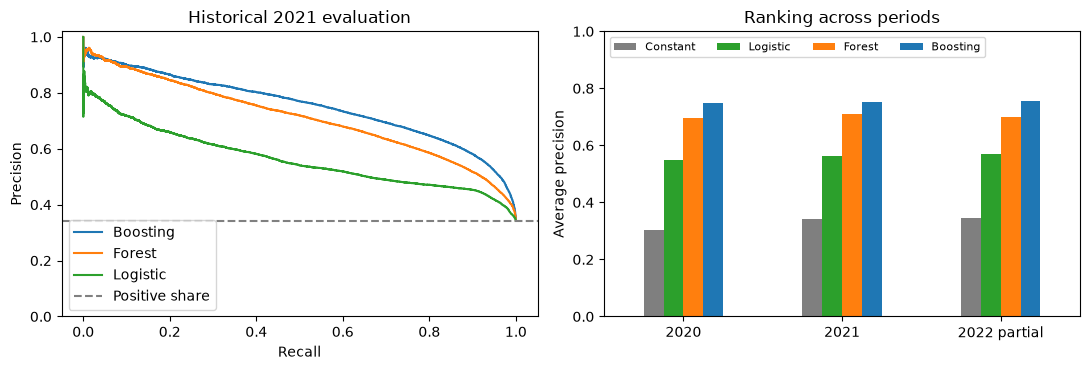

In [22]:
model_colors = {"Constant": "tab:gray", "Logistic": "tab:green", "Forest": "tab:orange", "Boosting": "tab:blue"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name in ["Boosting", "Forest", "Logistic"]:
    precision, recall, _ = precision_recall_curve(y["test"], predictions["test"][name])
    axes[0].plot(recall, precision, label=name, color=model_colors[name])
axes[0].axhline(y["test"].mean(), color="gray", linestyle="--", label="Positive share")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Historical 2021 evaluation", ylim=(0, 1.02))
axes[0].legend()
ranking = scores.pivot(index="Period", columns="Model", values="AP").reindex(["validation", "test", "stress"])
ranking.index = ["2020", "2021", "2022 partial"]
ranking[["Constant", "Logistic", "Forest", "Boosting"]].plot.bar(ax=axes[1], rot=0, color=model_colors)
axes[1].set(ylabel="Average precision", xlabel="", title="Ranking across periods", ylim=(0, 1))
axes[1].legend(loc="upper left", ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "06_evaluation.png")
plt.show()

Better ranking does not remove the precision-recall tradeoff. A more permissive
threshold finds more positives but also creates more false alerts. AP and
ROC-AUC describe ranking; they do not show that the numerical scores are
calibrated probabilities.

### 4.3 Understand the remaining mistakes

We inspect the 2021 confusion matrix at the fixed F1 threshold and check
recall separately for Severity 3 and 4. This avoids letting the common level 3
hide the rare level 4. These diagnostics do not select a new model or threshold.

In [23]:
positive_test = predictions["test"]["Boosting"] >= thresholds["Boosting"]
matrix = confusion_matrix(y["test"], positive_test, labels=[0, 1])
display(pd.DataFrame(matrix, index=["Actual low impact", "Actual high impact"],
    columns=["Predicted low impact", "Predicted high impact"]))
severity_diagnostics = []
for level in [3, 4]:
    mask = raw_clean["test"].Severity.eq(level).to_numpy()
    severity_diagnostics.append({"Severity": level, "Events": int(mask.sum()),
        "Recall (%)": round(100 * positive_test[mask].mean(), 1)})
display(pd.DataFrame(severity_diagnostics))
test_boosting = scores[(scores.Period == "test") & (scores.Model == "Boosting")].iloc[0]
display(Markdown(f"At the fixed threshold, boosting finds about **{100*test_boosting.Recall:.0f}%** "
    f"of high-impact events. About **{100*test_boosting.Precision:.0f}%** of its positive predictions "
    "are actually high-impact records. Both missed events and false alerts remain."))

,Predicted low impact,Predicted high impact
Actual low impact,50894,14832
Actual high impact,6923,27350


,Severity,Events,Recall (%)
0,3,33452,79.8
1,4,821,78.4


At the fixed threshold, boosting finds about **80%** of high-impact events. About **65%** of its positive predictions are actually high-impact records. Both missed events and false alerts remain.

The overall binary metrics are mostly driven by Severity 3. The smaller count
for level 4 makes its recall less secure as a general conclusion. The matrix
describes errors under our study labels, not injury outcomes or operational
intervention costs.

### 4.4 Look for patterns in errors by hour and by State

As a first descriptive analysis we group the 2021 accidents by start-hour range
and by State (the ten most frequent States of the sample). For each group we show
the number of positives and negatives, the share of positives that the model
misses and the share of negatives that it flags. Location was the most important
group in 3.8, so we want to see whether the errors are spread evenly over States.
A difference between groups can come from the mix of accidents; it is not evidence
of a cause.

In [24]:
errors = pd.DataFrame({"Actual": y["test"].astype(bool), "Predicted": positive_test,
    "Start hour": pd.cut(raw_clean["test"]._t.dt.hour, bins=[-1, 5, 11, 17, 23],
                         labels=["00-05", "06-11", "12-17", "18-23"]),
    "State": raw_clean["test"].State})

def error_rates(frame, column):
    """Share of missed positives and of false alerts for each value of a column."""
    rows = []
    for value, part in frame.groupby(column, observed=True):
        positives, negatives = part[part.Actual], part[~part.Actual]
        rows.append({column: str(value), "Events": len(part), "Positives": len(positives),
            "Negatives": len(negatives),
            "Missed positives (%)": 100 * (~positives.Predicted).mean(),
            "False positives (%)": 100 * negatives.Predicted.mean()})
    return pd.DataFrame(rows)

error_by_hour = error_rates(errors, "Start hour")
top_states = errors.State.value_counts().head(10).index
error_by_state = error_rates(errors[errors.State.isin(top_states)], "State")
error_by_state = error_by_state.sort_values("Events", ascending=False).reset_index(drop=True)
display(error_by_hour.round(1))
display(error_by_state.round(1))
error_by_hour.to_csv(REPORTS / "errors_by_hour.csv", index=False)
error_by_state.to_csv(REPORTS / "errors_by_state.csv", index=False)
missed = error_by_state.set_index("State")["Missed positives (%)"]
display(Markdown(f"Among these States, the share of missed positives goes from **{missed.min():.0f}%** "
    f"({missed.idxmin()}) to **{missed.max():.0f}%** ({missed.idxmax()})."))

,Start hour,Events,Positives,Negatives,Missed positives (%),False positives (%)
0,00-05,10439,2809,7630,24.5,25.7
1,06-11,45973,11378,34595,29.3,20.1
2,12-17,29611,13467,16144,15.0,25.7
3,18-23,13976,6619,7357,13.4,24.1


,State,Events,Positives,Negatives,Missed positives (%),False positives (%)
0,CA,16475,5028,11447,12.9,29.5
1,FL,9058,2545,6513,15.2,22.9
2,TX,8354,3456,4898,29.5,16.1
3,SC,6909,874,6035,49.5,7.5
4,NC,5595,862,4733,57.0,5.0
5,IL,5134,3462,1672,19.6,12.1
6,NY,3725,1501,2224,15.0,29.3
7,PA,3227,994,2233,26.6,16.1
8,AL,3141,853,2288,44.2,16.0
9,VA,3001,1522,1479,8.5,32.0


Among these States, the share of missed positives goes from **9%** (VA) to **57%** (NC).

In this sample, the share of missed positives is higher in the morning than in the
evening. The second table and the sentence under it show how much this share
changes between States. These tables describe our errors; they do not explain
them: the mix of accidents differs between hours and States, and the numbers of
positives and negatives behind each rate differ too. We keep the model fixed
instead of tuning it on this historical evaluation.

### 4.5 Distinguish a classification threshold from an alert budget

Selecting only the highest 10% of scores is a different decision from the
F1 threshold. We report the main model under both policies. Ties in the budget
are broken using event priorities independent of the labels. The budget is
retrospective, not a validated streaming alert service.

In [25]:
policies = pd.DataFrame([
    {"Policy": "Validation-selected F1 threshold", "Precision (%)": 100 * test_boosting.Precision,
     "Recall (%)": 100 * test_boosting.Recall},
    {"Policy": "Highest 10% of scores", "Precision (%)": 100 * test_boosting["Precision top 10%"],
     "Recall (%)": 100 * test_boosting["Recall top 10%"]}])
display(policies.round(1))

,Policy,Precision (%),Recall (%)
0,Validation-selected F1 threshold,64.8,79.8
1,Highest 10% of scores,84.7,24.7


Concentrating on fewer events can raise precision while finding a smaller
share of all positives. These recalls should never be presented as the same
measure. A deployment policy would also need costs, publication times and
probability calibration, which are outside this study.

## 5. Conclusion

We bring the main observations together, keeping the numerical summary short.
The following paragraph uses the scores calculated in this execution.

In [26]:
partial_boosting = scores[(scores.Period == "stress") & (scores.Model == "Boosting")].iloc[0]
display(Markdown(f"Our selected boosting model reaches **AP {test_boosting.AP:.3f}** "
    f"in the historical 2021 evaluation and **{partial_boosting.AP:.3f}** in the available part of 2022. "
    "It improves on the selected forest, the logistic regression and the constant reference "
    "under the common protocol. "
    "The main choices are a larger training sample and a more capable boosting configuration; "
    "the weather category limit is a smaller refinement."))

Our selected boosting model reaches **AP 0.752** in the historical 2021 evaluation and **0.754** in the available part of 2022. It improves on the selected forest, the logistic regression and the constant reference under the common protocol. The main choices are a larger training sample and a more capable boosting configuration; the weather category limit is a smaller refinement.

Combining the approaches helped us see that preprocessing and evaluation belong
together. Kamar's exploration and first models made the preparation choices
concrete, and Yanis's checks on events and time made the comparisons easier to
interpret. A higher score only means something when we know the data, the allowed
information and the prediction time behind it.

The model still makes mistakes. Our results concern one data source, most
positives are Severity 3, and 2022 is incomplete. Weather observation times do
not tell us when the readings were published, so the update is a later
prediction. We have not calibrated the scores as probabilities and we have not
confirmed the model on a new, unseen period. With more time we would study
calibration, analyse the errors at a finer level (cities, road types), test a
split with September boundaries like Kamar's preparation (it matches the end of
Source2 on 8 September 2022), and evaluate on a later independent period.

## Appendix A. Full data dictionary

Each original column and each derived input is defined below. Expand a field
to see its type, unit, role, time reference and treatment. The same dictionary
is exported to `data/final_notebook/reports/data_dictionary.csv`. The expandable
entries use lightweight HTML, without an interactive plotting dependency.

In [27]:
from html import escape
entries = []
for row in dictionary.to_dict("records"):
    body = "".join(f"<dt><b>{escape(key)}</b></dt><dd>{escape(str(value))}</dd>"
        for key, value in row.items() if key not in ["Column", "Meaning"])
    entries.append(f"<details style='margin:6px 0'><summary><b>{escape(row['Column'])}</b>: "
        f"{escape(row['Meaning'])}</summary><dl>{body}</dl></details>")
display(HTML("".join(entries)))

The dictionary distinguishes excluded columns from fields used only for an
audit. The data's measurement units are kept explicit. The availability
descriptions are study assumptions where publication times are absent.

## Appendix B. Reproduction and consistency

We check the periods, the uniqueness of events, the excluded inputs and the fixed
category lists. Boosting must reproduce its recorded validation AP and threshold
exactly: a constant input such as Turning_Loop cannot be used by any split, so
removing it leaves the model unchanged. The forest is different. Its recorded
result used 34 inputs and the training median for wind chill; it now uses 33
inputs and the wind chill option chosen in 3.4. With one input fewer, the random
feature subsets at each split also change, so we show the recorded and the
current forest AP side by side instead of requiring them to match.
These are internal consistency checks, not an independent validation of the
labels. A rough proximity diagnostic uses explicit nanosecond timestamps; it
never removes nearby events and does not change the model.

In [28]:
checks = {}
years = {"train": {2016, 2017, 2018, 2019}, "validation": {2020}, "test": {2021}, "stress": {2022}}
for split, frame in raw_clean.items():
    checks[f"{split}: Source2, years and unique events"] = bool(frame.Source.eq("Source2").all()
        and set(frame._t.dt.year.unique()) <= years[split] and frame._event.is_unique)
    checks[f"{split}: 33 inputs, target excluded"] = X[split].shape[1] == 33 and not set(X[split]) & FORBIDDEN
    for column in category_prep.vocab:
        assert X[split][column].cat.categories.equals(X["train"][column].cat.categories)
for first, second in itertools.combinations(raw_clean, 2):
    checks[f"{first}/{second}: no temporal/event overlap"] = bool(
        raw_clean[first]._t.max() < raw_clean[second]._t.min()
        and not np.intersect1d(raw_clean[first]._event, raw_clean[second]._event).size)
checks["Expected sample sizes"] = [len(y[s]) for s in y] == [500000, 50000, 99999, 50000]
checks["Turning_Loop constant and excluded"] = bool(features["train"].Turning_Loop.eq(0).all()
    and all("Turning_Loop" not in X[s] and "Turning_Loop" not in forest_categories.columns for s in X))
checks["Complete original and derived dictionary"] = len(dictionary) == len(preview.columns) + 4
frozen = json.loads((COMPARISONS / "frozen_selection.json").read_text())
checks["Selection used validation only"] = frozen["test_used_for_selection"] is False
references = {r["family"]: r for r in frozen["selected"]}
actual = validation_scores[validation_scores.Model.eq("Boosting")].iloc[0]
checks["Boosting: recorded validation reproduced"] = bool(
    np.isclose(actual.AP, references["hgb"]["ap"], atol=1e-8, rtol=0)
    and np.isclose(thresholds["Boosting"], references["hgb"]["threshold"], atol=1e-8, rtol=0))
forest_validation = validation_scores[validation_scores.Model.eq("Forest")].iloc[0]
display(pd.DataFrame({"Recorded forest (34 inputs, median only)": [references["rf"]["ap"]],
    "Current forest": [forest_validation.AP]}, index=["Validation AP"]).round(4))
probe = raw_clean["train"].iloc[:50000].copy()
ns_keys = nearby_keys(probe.assign(Start_Time=probe._t.astype("datetime64[ns]")))
us_keys = nearby_keys(probe.assign(Start_Time=probe._t.astype("datetime64[us]")))
checks["Proximity independent of timestamp unit"] = bool(np.array_equal(ns_keys, us_keys))
check_table = pd.DataFrame({"Check": checks.keys(), "Passed": checks.values()})
check_table.to_csv(REPORTS / "consistency_checks.csv", index=False)
assert check_table.Passed.all(), check_table.loc[~check_table.Passed]
display(Markdown("The period, preparation and reproduction checks passed. Full details are saved in the reports folder."))

,"Recorded forest (34 inputs, median only)",Current forest
Validation AP,0.6961,0.6965


The period, preparation and reproduction checks passed. Full details are saved in the reports folder.

The notebook uses `traffic_impact/` modules, the requirements files and the
small common-comparison tables under `results/final_notebook_comparison/`.
Keep that structure when reproducing it. Put the CSV in `data/` or set
CSV_PATH, then run all cells in order. Caches, generated reports and figures
are stored in `data/final_notebook/` and can be regenerated. Do not submit the
raw CSV, caches or fitted models.

Internal checks support reproducibility within this setup; they do not prove
the absence of every possible bias. The complete comparison exports remain
available for inspecting the wider search and its limits.